In [2]:
import pandas as pd
import numpy as np

In [22]:
data = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Tugas 1/data_2_penjualan_online.csv')
data.head(10)

,Bulan,Kategori_Produk,Kota,Metode_Pembayaran,Jumlah_Terjual,Harga_Satuan,Diskon_Persen,Rating_Pelanggan
0,Januari,Elektronik,Medan,COD,25.0,1933000.0,20.0,3.9
1,Januari,Fashion,Jakarta,E-Wallet,35.0,257000.0,NaN,4.5
2,Januari,Makanan,Bandung,Transfer Bank,36.0,25.0,NaN,4.4
3,Januari,Makanan,Medan,Transfer Bank,34.0,50000.0,0.0,0.0
4,Januari,Fashion,Jakarta,Transfer Bank,NaN,231000.0,15.0,4.1
5,Januri,Olahraga,Makassar,Transfer Bank,25.0,0.0,0.0,3.0
6,Januari,FASHION,Bandung,Kartu Kredit,35.0,308000.0,5.0,4.5
7,NaN,Kecantikan,Makassar,COD,NaN,163000.0,90.0,3.7
8,Januari,Elektronik,Jakarta,E-Wallet,NaN,3160000.0,20.0,4.0
9,Januari,Fashion,Surabaya,Kartu Kredit,30.0,181000.0,15.0,4.2


**1. DATA CLEANSING**

*1. Mistake During Data Entry*

1.1 Check Writing Variations

In [24]:
for col in ['Bulan', 'Kategori_Produk', 'Kota', 'Metode_Pembayaran']:
    print(data.groupby(col).size())
    print()

Bulan
  April          1
  Desember       1
  Februari       1
  Mei            1
  September      1
-                1
Agustus         10
Agustus          1
Agutus           1
April            5
Desember        10
Desmber          1
FEBRUARI         1
Februari         8
JULI             1
Januari          8
Januri           1
Jul              1
Juli             7
Juni             8
MEI              1
Mai              1
Maret            8
Maret            1
Mei              8
November         6
Oktober          6
September        9
September        1
Unknown          1
februari         1
juni             1
maret            1
mei              1
dtype: int64

Kategori_Produk
  Fashion        1
  Makanan        1
 Kecantikan      1
-                1
ELEKTRONIK       1
Elektonik        3
Elektronik      22
FASHION          2
Fashion         13
Fashion          1
Fashon           1
Kecantikan      13
Kecantikan       1
Kecantikn        1
Makanan         31
Makanan          1
Makanan       

1.2 Standardize Letter Case

In [25]:
for col in ['Bulan', 'Kategori_Produk', 'Kota', 'Metode_Pembayaran']:
    data[col] = data[col].str.upper()
data[['Bulan', 'Kategori_Produk', 'Kota', 'Metode_Pembayaran']].head(10)

,Bulan,Kategori_Produk,Kota,Metode_Pembayaran
0,JANUARI,ELEKTRONIK,MEDAN,COD
1,JANUARI,FASHION,JAKARTA,E-WALLET
2,JANUARI,MAKANAN,BANDUNG,TRANSFER BANK
3,JANUARI,MAKANAN,MEDAN,TRANSFER BANK
4,JANUARI,FASHION,JAKARTA,TRANSFER BANK
5,JANURI,OLAHRAGA,MAKASSAR,TRANSFER BANK
6,JANUARI,FASHION,BANDUNG,KARTU KREDIT
7,NaN,KECANTIKAN,MAKASSAR,COD
8,JANUARI,ELEKTRONIK,JAKARTA,E-WALLET
9,JANUARI,FASHION,SURABAYA,KARTU KREDIT


*2. Redundant Whitespace*

2.1 Remove Excess Whitespace

In [26]:
data = data.apply(lambda x: x.str.strip() if x.dtype == "object" else x)
data = data.apply(lambda x: x.str.replace(r'\s+', ' ', regex=True) if x.dtype == "object" else x)
data[['Bulan', 'Kategori_Produk', 'Kota', 'Metode_Pembayaran']].head(10)

,Bulan,Kategori_Produk,Kota,Metode_Pembayaran
0,JANUARI,ELEKTRONIK,MEDAN,COD
1,JANUARI,FASHION,JAKARTA,E-WALLET
2,JANUARI,MAKANAN,BANDUNG,TRANSFER BANK
3,JANUARI,MAKANAN,MEDAN,TRANSFER BANK
4,JANUARI,FASHION,JAKARTA,TRANSFER BANK
5,JANURI,OLAHRAGA,MAKASSAR,TRANSFER BANK
6,JANUARI,FASHION,BANDUNG,KARTU KREDIT
7,NaN,KECANTIKAN,MAKASSAR,COD
8,JANUARI,ELEKTRONIK,JAKARTA,E-WALLET
9,JANUARI,FASHION,SURABAYA,KARTU KREDIT


2.2 Fix Typos

In [27]:
data["Kategori_Produk"] = data["Kategori_Produk"].replace("ELEKTONIK", "ELEKTRONIK")
data["Kategori_Produk"] = data["Kategori_Produk"].replace("FASHON", "FASHION")
data["Kategori_Produk"] = data["Kategori_Produk"].replace("MAKANNAN", "MAKANAN")
data["Kategori_Produk"] = data["Kategori_Produk"].replace("KECANTIKN", "KECANTIKAN")
data["Kategori_Produk"] = data["Kategori_Produk"].replace("OLAH RAGA", "OLAHRAGA")

data["Kota"] = data["Kota"].replace("SURABYA", "SURABAYA")
data["Kota"] = data["Kota"].replace("JAKRTA", "JAKARTA")
data["Kota"] = data["Kota"].replace("BANDUG", "BANDUNG")
data["Kota"] = data["Kota"].replace("MEDN", "MEDAN")
data["Kota"] = data["Kota"].replace("MAKASAR", "MAKASSAR")

data["Metode_Pembayaran"] = data["Metode_Pembayaran"].replace("TRANSFER BNK", "TRANSFER BANK")
data["Metode_Pembayaran"] = data["Metode_Pembayaran"].replace("E WALLET", "E-WALLET")
data["Metode_Pembayaran"] = data["Metode_Pembayaran"].replace("EWALLET", "E-WALLET")
data["Metode_Pembayaran"] = data["Metode_Pembayaran"].replace("COD.", "COD")
data["Metode_Pembayaran"] = data["Metode_Pembayaran"].replace("KARTU KREDITT", "KARTU KREDIT")

data["Bulan"] = data["Bulan"].replace("JANURI", "JANUARI")
data["Bulan"] = data["Bulan"].replace("FEBUARI", "FEBRUARI")
data["Bulan"] = data["Bulan"].replace("MART", "MARET")
data["Bulan"] = data["Bulan"].replace("APRILL", "APRIL")
data["Bulan"] = data["Bulan"].replace("MAI", "MEI")
data["Bulan"] = data["Bulan"].replace("JUN", "JUNI")
data["Bulan"] = data["Bulan"].replace("JUL", "JULI")
data["Bulan"] = data["Bulan"].replace("AGUTUS", "AGUSTUS")
data["Bulan"] = data["Bulan"].replace("SEPETMBER", "SEPTEMBER")
data["Bulan"] = data["Bulan"].replace("OKOTBER", "OKTOBER")
data["Bulan"] = data["Bulan"].replace("NOPEMBER", "NOVEMBER")
data["Bulan"] = data["Bulan"].replace("DESMBER", "DESEMBER")

for col in ['Bulan', 'Kategori_Produk', 'Kota', 'Metode_Pembayaran']:
    print(data.groupby(col).size())
    print()

Bulan
-             1
AGUSTUS      12
APRIL         6
DESEMBER     12
FEBRUARI     11
JANUARI       9
JULI          9
JUNI          9
MARET        10
MEI          12
NOVEMBER      6
OKTOBER       6
SEPTEMBER    11
UNKNOWN       1
dtype: int64

Kategori_Produk
-              1
ELEKTRONIK    27
FASHION       18
KECANTIKAN    16
MAKANAN       35
OLAHRAGA      17
UNKNOWN        1
dtype: int64

Kota
-            1
BANDUNG     19
JAKARTA     26
MAKASSAR    24
MEDAN       22
SURABAYA    22
UNKNOWN      1
dtype: int64

Metode_Pembayaran
-                 1
COD              22
E-WALLET         37
KARTU KREDIT     27
TRANSFER BANK    27
UNKNOWN           1
dtype: int64



*3. Impossible Value*

3.1 Display Impossible Values

In [28]:
print(data[data["Jumlah_Terjual"] < 0])
print(data[data["Harga_Satuan"] < 0])
print(data[data["Diskon_Persen"] < 0])
print(data[data["Diskon_Persen"] > 100])
print(data[data["Rating_Pelanggan"] < 1])
print(data[data["Rating_Pelanggan"] > 5])

   Bulan Kategori_Produk      Kota Metode_Pembayaran  Jumlah_Terjual  \
48   MEI      KECANTIKAN  SURABAYA               COD            -8.0   
49   MEI      ELEKTRONIK     MEDAN               COD           -15.0   

    Harga_Satuan  Diskon_Persen  Rating_Pelanggan  
48      222000.0            NaN               4.3  
49     3338000.0            5.0               4.0  
      Bulan Kategori_Produk     Kota Metode_Pembayaran  Jumlah_Terjual  \
81  AGUSTUS             NaN  BANDUNG               COD            36.0   

    Harga_Satuan  Diskon_Persen  Rating_Pelanggan  
81     -250000.0            5.0               3.9  
   Bulan Kategori_Produk Kota Metode_Pembayaran  Jumlah_Terjual  Harga_Satuan  \
63  JULI        OLAHRAGA  NaN          E-WALLET            32.0      286000.0   

    Diskon_Persen  Rating_Pelanggan  
63          -10.0               3.7  
         Bulan Kategori_Produk      Kota Metode_Pembayaran  Jumlah_Terjual  \
91   SEPTEMBER      ELEKTRONIK   JAKARTA      KARTU KREDI

3.2 Solution 2: Drop Rows

In [29]:
print('Jumlah baris sebelum:', data.shape[0])

data = data.drop(data[(data["Jumlah_Terjual"] < 0)].index)
data = data.drop(data[(data["Harga_Satuan"] < 0)].index)
data = data.drop(data[(data["Diskon_Persen"] < 0) | (data["Diskon_Persen"] > 100)].index)
data = data.drop(data[(data["Rating_Pelanggan"] < 1) | (data["Rating_Pelanggan"] > 5)].index)

print('Jumlah baris sesudah:', data.shape[0])
data.head(10)

Jumlah baris sebelum: 120
Jumlah baris sesudah: 109


,Bulan,Kategori_Produk,Kota,Metode_Pembayaran,Jumlah_Terjual,Harga_Satuan,Diskon_Persen,Rating_Pelanggan
0,JANUARI,ELEKTRONIK,MEDAN,COD,25.0,1933000.0,20.0,3.9
1,JANUARI,FASHION,JAKARTA,E-WALLET,35.0,257000.0,NaN,4.5
2,JANUARI,MAKANAN,BANDUNG,TRANSFER BANK,36.0,25.0,NaN,4.4
4,JANUARI,FASHION,JAKARTA,TRANSFER BANK,NaN,231000.0,15.0,4.1
5,JANUARI,OLAHRAGA,MAKASSAR,TRANSFER BANK,25.0,0.0,0.0,3.0
6,JANUARI,FASHION,BANDUNG,KARTU KREDIT,35.0,308000.0,5.0,4.5
7,NaN,KECANTIKAN,MAKASSAR,COD,NaN,163000.0,90.0,3.7
8,JANUARI,ELEKTRONIK,JAKARTA,E-WALLET,NaN,3160000.0,20.0,4.0
9,JANUARI,FASHION,SURABAYA,KARTU KREDIT,30.0,181000.0,15.0,4.2
10,FEBRUARI,FASHION,SURABAYA,TRANSFER BANK,25.0,194000.0,10.0,4.3


*4. Missing Value*

4.1 Check Missing Value

In [30]:
data.isnull().sum()

,0
Bulan,5
Kategori_Produk,4
Kota,4
Metode_Pembayaran,5
Jumlah_Terjual,7
Harga_Satuan,8
Diskon_Persen,7
Rating_Pelanggan,8


4.2 Display Rows

In [31]:
data[data.isnull().any(axis=1)].head(10)

,Bulan,Kategori_Produk,Kota,Metode_Pembayaran,Jumlah_Terjual,Harga_Satuan,Diskon_Persen,Rating_Pelanggan
1,JANUARI,FASHION,JAKARTA,E-WALLET,35.0,257000.0,NaN,4.5
2,JANUARI,MAKANAN,BANDUNG,TRANSFER BANK,36.0,25.0,NaN,4.4
4,JANUARI,FASHION,JAKARTA,TRANSFER BANK,NaN,231000.0,15.0,4.1
7,NaN,KECANTIKAN,MAKASSAR,COD,NaN,163000.0,90.0,3.7
8,JANUARI,ELEKTRONIK,JAKARTA,E-WALLET,NaN,3160000.0,20.0,4.0
18,FEBRUARI,OLAHRAGA,BANDUNG,TRANSFER BANK,28.0,NaN,25.0,4.1
19,UNKNOWN,OLAHRAGA,BANDUNG,TRANSFER BANK,32.0,NaN,NaN,4.4
20,FEBRUARI,OLAHRAGA,SURABAYA,KARTU KREDIT,29.0,267000.0,NaN,4.1
21,FEBRUARI,FASHION,JAKARTA,KARTU KREDIT,39.0,260000.0,10.0,NaN
28,MARET,MAKANAN,BANDUNG,E-WALLET,30.0,NaN,0.0,3.9


4.3 Visualize Missing Values

<Axes: >

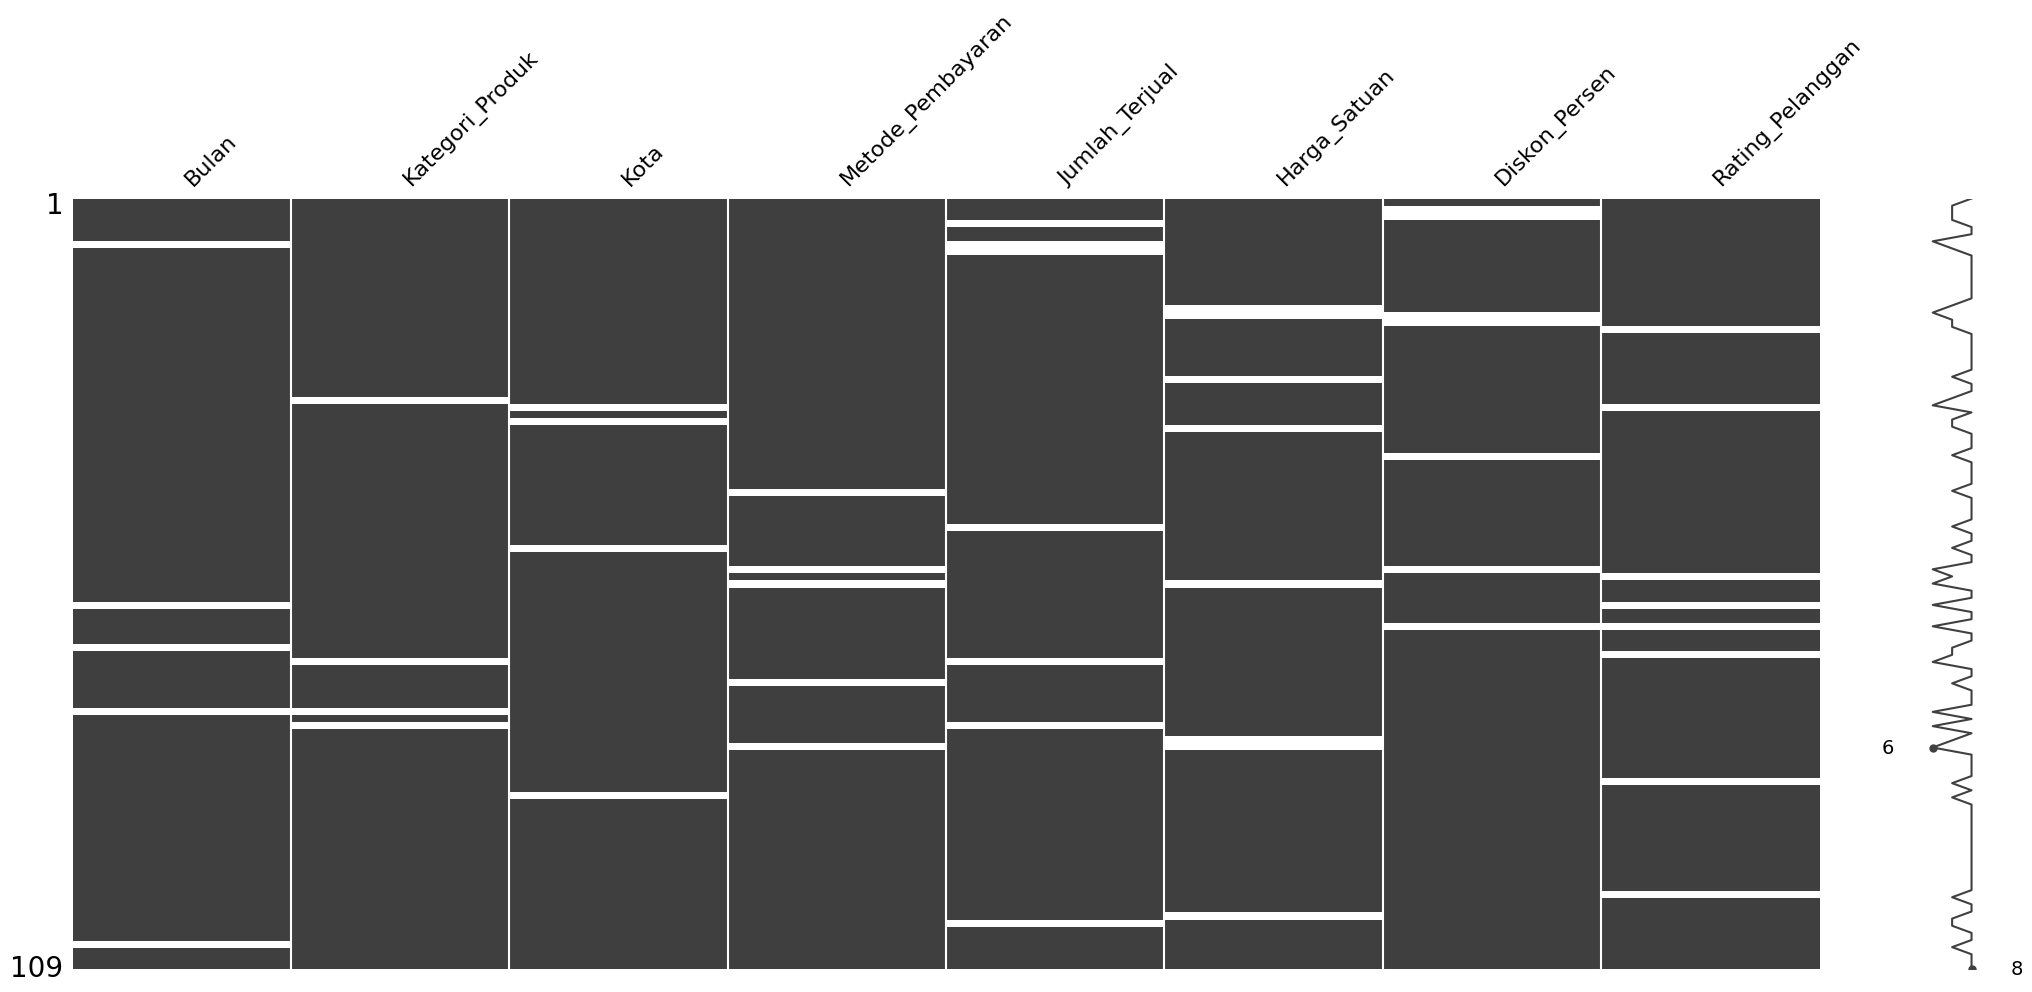

In [32]:
!pip install missingno
import missingno as msno

msno.matrix(data)

4.4 Solution 1: Omit the Value

In [33]:
data_drop_row = data.dropna()
data_drop_col = data.dropna(axis=1)

print('Data asli (baris, kolom)          :', data.shape)
print('Setelah hapus baris bermissing    :', data_drop_row.shape)
print('Setelah hapus kolom bermissing    :', data_drop_col.shape)

Data asli (baris, kolom)          : (109, 8)
Setelah hapus baris bermissing    : (72, 8)
Setelah hapus kolom bermissing    : (109, 0)


4.5 Solution 2: Set Value to NULL

In [34]:
data_null = data.replace(["-", "UNKNOWN"], np.nan)
data_null[['Harga_Satuan']] = data_null[['Harga_Satuan']].replace(0, np.nan)
data = data_null
data.isnull().sum()

,0
Bulan,7
Kategori_Produk,6
Kota,6
Metode_Pembayaran,7
Jumlah_Terjual,7
Harga_Satuan,11
Diskon_Persen,7
Rating_Pelanggan,8


4.6 Descriptive Statistics Before Imputation

In [35]:
print(data[['Jumlah_Terjual', 'Harga_Satuan', 'Diskon_Persen', 'Rating_Pelanggan']].describe())
print()
print(data[['Bulan', 'Kategori_Produk', 'Kota', 'Metode_Pembayaran']].describe())

       Jumlah_Terjual  Harga_Satuan  Diskon_Persen  Rating_Pelanggan
count      102.000000  9.800000e+01     102.000000        101.000000
mean        37.911765  1.254951e+06      14.264706          4.080198
std         51.850910  4.568711e+06      13.394196          0.442949
min         20.000000  2.300000e+01       0.000000          3.000000
25%         26.250000  4.000000e+04       5.000000          3.800000
50%         30.000000  2.040000e+05      15.000000          4.100000
75%         34.750000  4.435000e+05      20.000000          4.400000
max        420.000000  3.500000e+07      90.000000          5.000000

           Bulan Kategori_Produk     Kota Metode_Pembayaran
count        102             103      103               102
unique        12               5        5                 4
top     DESEMBER         MAKANAN  JAKARTA          E-WALLET
freq          11              33       24                35


4.7 Solution 3: Impute a Static Value to 0

In [36]:
data_fill0 = data.fillna(0)
data_fill0.head(10)

,Bulan,Kategori_Produk,Kota,Metode_Pembayaran,Jumlah_Terjual,Harga_Satuan,Diskon_Persen,Rating_Pelanggan
0,JANUARI,ELEKTRONIK,MEDAN,COD,25.0,1933000.0,20.0,3.9
1,JANUARI,FASHION,JAKARTA,E-WALLET,35.0,257000.0,0.0,4.5
2,JANUARI,MAKANAN,BANDUNG,TRANSFER BANK,36.0,25.0,0.0,4.4
4,JANUARI,FASHION,JAKARTA,TRANSFER BANK,0.0,231000.0,15.0,4.1
5,JANUARI,OLAHRAGA,MAKASSAR,TRANSFER BANK,25.0,0.0,0.0,3.0
6,JANUARI,FASHION,BANDUNG,KARTU KREDIT,35.0,308000.0,5.0,4.5
7,0,KECANTIKAN,MAKASSAR,COD,0.0,163000.0,90.0,3.7
8,JANUARI,ELEKTRONIK,JAKARTA,E-WALLET,0.0,3160000.0,20.0,4.0
9,JANUARI,FASHION,SURABAYA,KARTU KREDIT,30.0,181000.0,15.0,4.2
10,FEBRUARI,FASHION,SURABAYA,TRANSFER BANK,25.0,194000.0,10.0,4.3


4.8 Solution 3: Impute with the Mean and Mode

In [37]:
data["Jumlah_Terjual"]   = data["Jumlah_Terjual"].fillna(data["Jumlah_Terjual"].mean())
data["Harga_Satuan"]     = data["Harga_Satuan"].fillna(data["Harga_Satuan"].mean())
data["Diskon_Persen"]    = data["Diskon_Persen"].fillna(data["Diskon_Persen"].mean())
data["Rating_Pelanggan"] = data["Rating_Pelanggan"].fillna(data["Rating_Pelanggan"].mean())

data["Bulan"]             = data["Bulan"].fillna(data["Bulan"].mode()[0])
data["Kategori_Produk"]   = data["Kategori_Produk"].fillna(data["Kategori_Produk"].mode()[0])
data["Kota"]              = data["Kota"].fillna(data["Kota"].mode()[0])
data["Metode_Pembayaran"] = data["Metode_Pembayaran"].fillna(data["Metode_Pembayaran"].mode()[0])

data.isnull().sum()

,0
Bulan,0
Kategori_Produk,0
Kota,0
Metode_Pembayaran,0
Jumlah_Terjual,0
Harga_Satuan,0
Diskon_Persen,0
Rating_Pelanggan,0


4.9 Descriptive Statistics After Imputation

In [38]:
data[['Jumlah_Terjual', 'Harga_Satuan', 'Diskon_Persen', 'Rating_Pelanggan']].describe()

,Jumlah_Terjual,Harga_Satuan,Diskon_Persen,Rating_Pelanggan
count,109.000000,1.090000e+02,109.000000,109.000000
mean,37.911765,1.254951e+06,14.264706,4.080198
std,50.142409,4.329798e+06,12.952854,0.426228
min,20.000000,2.300000e+01,0.000000,3.000000
25%,27.000000,4.000000e+04,5.000000,3.800000
50%,31.000000,2.400000e+05,14.264706,4.080198
75%,35.000000,1.254951e+06,20.000000,4.400000
max,420.000000,3.500000e+07,90.000000,5.000000


*5. Outlier*

5.1 Detecting Outliers

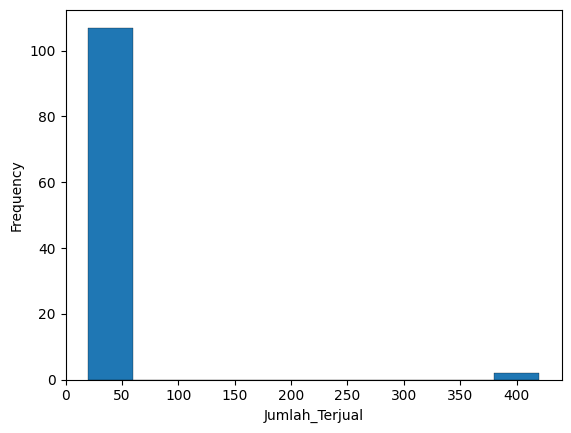

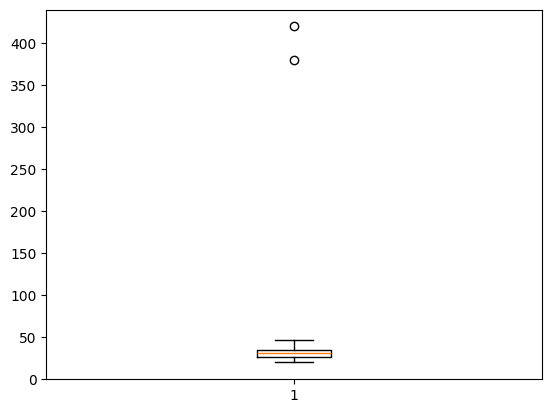

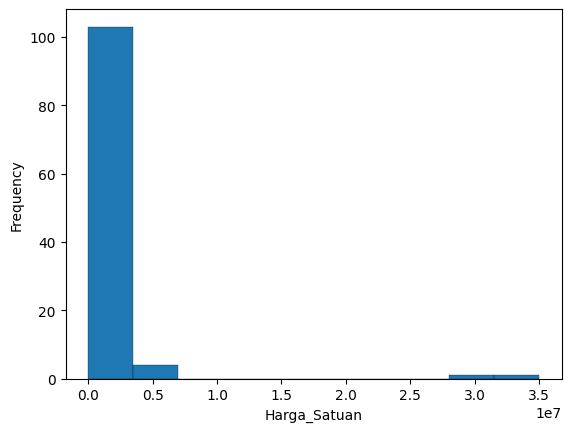

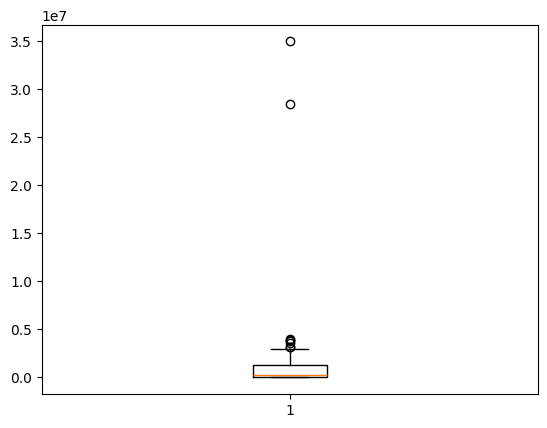

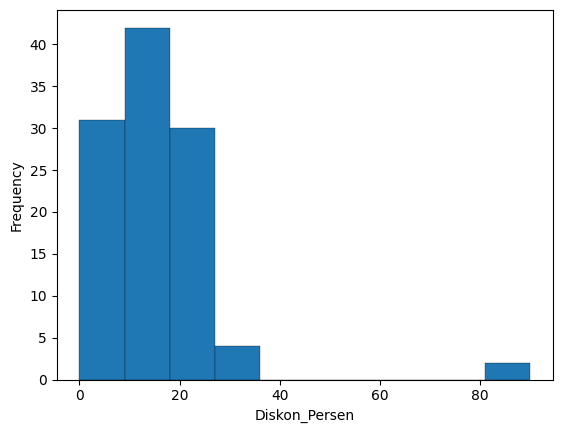

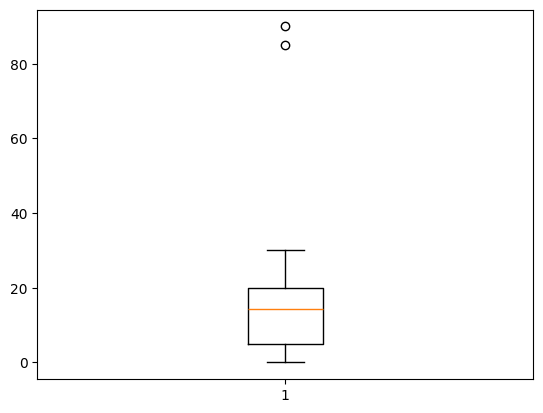

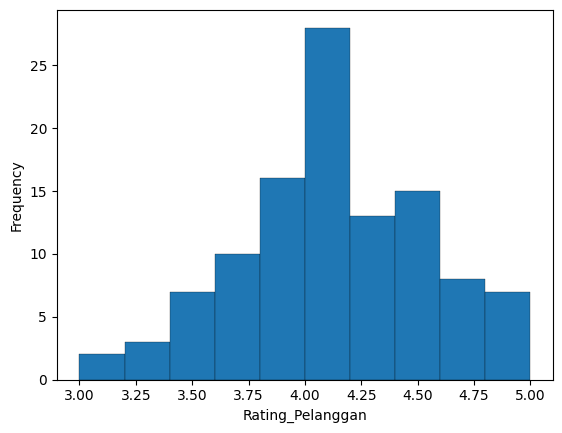

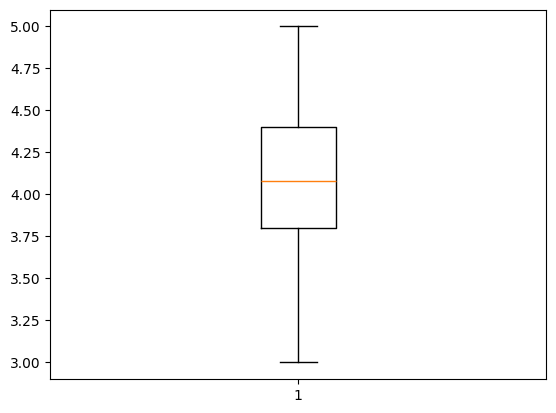

In [39]:
import matplotlib.pyplot as plt

for col in ['Jumlah_Terjual', 'Harga_Satuan', 'Diskon_Persen', 'Rating_Pelanggan']:
    plt.hist(data[col], edgecolor='black', linewidth=0.2)
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

    plt.boxplot(data[col])
    plt.show()

5.2 Reading the Plots

In [40]:
data[['Jumlah_Terjual', 'Harga_Satuan', 'Diskon_Persen', 'Rating_Pelanggan']].describe()

,Jumlah_Terjual,Harga_Satuan,Diskon_Persen,Rating_Pelanggan
count,109.000000,1.090000e+02,109.000000,109.000000
mean,37.911765,1.254951e+06,14.264706,4.080198
std,50.142409,4.329798e+06,12.952854,0.426228
min,20.000000,2.300000e+01,0.000000,3.000000
25%,27.000000,4.000000e+04,5.000000,3.800000
50%,31.000000,2.400000e+05,14.264706,4.080198
75%,35.000000,1.254951e+06,20.000000,4.400000
max,420.000000,3.500000e+07,90.000000,5.000000


5.3 Save Cleansing Result

In [54]:
data.to_csv('/content/drive/MyDrive/Colab Notebooks/Tugas 1/data_2_penjualan_online_clean.csv', index=False)
print('Saved:', data.shape)

Saved: (109, 11)


**2. DATA TRANSFORMATION**

*1. Transformation Input Data*

1.1 Copy Clean Data

In [41]:
data_clean = data.copy()
data_clean.head(8)

,Bulan,Kategori_Produk,Kota,Metode_Pembayaran,Jumlah_Terjual,Harga_Satuan,Diskon_Persen,Rating_Pelanggan
0,JANUARI,ELEKTRONIK,MEDAN,COD,25.000000,1.933000e+06,20.000000,3.9
1,JANUARI,FASHION,JAKARTA,E-WALLET,35.000000,2.570000e+05,14.264706,4.5
2,JANUARI,MAKANAN,BANDUNG,TRANSFER BANK,36.000000,2.500000e+01,14.264706,4.4
4,JANUARI,FASHION,JAKARTA,TRANSFER BANK,37.911765,2.310000e+05,15.000000,4.1
5,JANUARI,OLAHRAGA,MAKASSAR,TRANSFER BANK,25.000000,1.254951e+06,0.000000,3.0
6,JANUARI,FASHION,BANDUNG,KARTU KREDIT,35.000000,3.080000e+05,5.000000,4.5
7,DESEMBER,KECANTIKAN,MAKASSAR,COD,37.911765,1.630000e+05,90.000000,3.7
8,JANUARI,ELEKTRONIK,JAKARTA,E-WALLET,37.911765,3.160000e+06,20.000000,4.0


*2. Scaling*

2.1 Min-Max Scaling (Manual)

In [42]:
data = data_clean.copy()
data["Jumlah_Terjual"] = (data["Jumlah_Terjual"]-data["Jumlah_Terjual"].min())/(data["Jumlah_Terjual"].max()-data["Jumlah_Terjual"].min())
data["Jumlah_Terjual"] = data["Jumlah_Terjual"].round(3)
data.head(8)

,Bulan,Kategori_Produk,Kota,Metode_Pembayaran,Jumlah_Terjual,Harga_Satuan,Diskon_Persen,Rating_Pelanggan
0,JANUARI,ELEKTRONIK,MEDAN,COD,0.012,1.933000e+06,20.000000,3.9
1,JANUARI,FASHION,JAKARTA,E-WALLET,0.038,2.570000e+05,14.264706,4.5
2,JANUARI,MAKANAN,BANDUNG,TRANSFER BANK,0.040,2.500000e+01,14.264706,4.4
4,JANUARI,FASHION,JAKARTA,TRANSFER BANK,0.045,2.310000e+05,15.000000,4.1
5,JANUARI,OLAHRAGA,MAKASSAR,TRANSFER BANK,0.012,1.254951e+06,0.000000,3.0
6,JANUARI,FASHION,BANDUNG,KARTU KREDIT,0.038,3.080000e+05,5.000000,4.5
7,DESEMBER,KECANTIKAN,MAKASSAR,COD,0.045,1.630000e+05,90.000000,3.7
8,JANUARI,ELEKTRONIK,JAKARTA,E-WALLET,0.045,3.160000e+06,20.000000,4.0


2.2 Min-Max Scaling (Library)

In [43]:
from sklearn.preprocessing import MinMaxScaler
data["Jumlah_Terjual"] = MinMaxScaler().fit_transform(data[["Jumlah_Terjual"]])
data.head(8)

,Bulan,Kategori_Produk,Kota,Metode_Pembayaran,Jumlah_Terjual,Harga_Satuan,Diskon_Persen,Rating_Pelanggan
0,JANUARI,ELEKTRONIK,MEDAN,COD,0.012,1.933000e+06,20.000000,3.9
1,JANUARI,FASHION,JAKARTA,E-WALLET,0.038,2.570000e+05,14.264706,4.5
2,JANUARI,MAKANAN,BANDUNG,TRANSFER BANK,0.040,2.500000e+01,14.264706,4.4
4,JANUARI,FASHION,JAKARTA,TRANSFER BANK,0.045,2.310000e+05,15.000000,4.1
5,JANUARI,OLAHRAGA,MAKASSAR,TRANSFER BANK,0.012,1.254951e+06,0.000000,3.0
6,JANUARI,FASHION,BANDUNG,KARTU KREDIT,0.038,3.080000e+05,5.000000,4.5
7,DESEMBER,KECANTIKAN,MAKASSAR,COD,0.045,1.630000e+05,90.000000,3.7
8,JANUARI,ELEKTRONIK,JAKARTA,E-WALLET,0.045,3.160000e+06,20.000000,4.0


2.3 Z-score Standardization (Manual)

In [44]:
data = data_clean.copy()
data["Jumlah_Terjual"] = (data["Jumlah_Terjual"]- data["Jumlah_Terjual"].mean())/data["Jumlah_Terjual"].std()
data["Jumlah_Terjual"] = data["Jumlah_Terjual"].round(3)
data.head(8)

,Bulan,Kategori_Produk,Kota,Metode_Pembayaran,Jumlah_Terjual,Harga_Satuan,Diskon_Persen,Rating_Pelanggan
0,JANUARI,ELEKTRONIK,MEDAN,COD,-0.258,1.933000e+06,20.000000,3.9
1,JANUARI,FASHION,JAKARTA,E-WALLET,-0.058,2.570000e+05,14.264706,4.5
2,JANUARI,MAKANAN,BANDUNG,TRANSFER BANK,-0.038,2.500000e+01,14.264706,4.4
4,JANUARI,FASHION,JAKARTA,TRANSFER BANK,0.000,2.310000e+05,15.000000,4.1
5,JANUARI,OLAHRAGA,MAKASSAR,TRANSFER BANK,-0.258,1.254951e+06,0.000000,3.0
6,JANUARI,FASHION,BANDUNG,KARTU KREDIT,-0.058,3.080000e+05,5.000000,4.5
7,DESEMBER,KECANTIKAN,MAKASSAR,COD,0.000,1.630000e+05,90.000000,3.7
8,JANUARI,ELEKTRONIK,JAKARTA,E-WALLET,0.000,3.160000e+06,20.000000,4.0


2.4 Z-score Standardization (Library)

In [45]:
from sklearn.preprocessing import StandardScaler
data["Jumlah_Terjual"] = StandardScaler().fit_transform(data[['Jumlah_Terjual']])
data.head(8)

,Bulan,Kategori_Produk,Kota,Metode_Pembayaran,Jumlah_Terjual,Harga_Satuan,Diskon_Persen,Rating_Pelanggan
0,JANUARI,ELEKTRONIK,MEDAN,COD,-0.259121,1.933000e+06,20.000000,3.9
1,JANUARI,FASHION,JAKARTA,E-WALLET,-0.058195,2.570000e+05,14.264706,4.5
2,JANUARI,MAKANAN,BANDUNG,TRANSFER BANK,-0.038102,2.500000e+01,14.264706,4.4
4,JANUARI,FASHION,JAKARTA,TRANSFER BANK,0.000074,2.310000e+05,15.000000,4.1
5,JANUARI,OLAHRAGA,MAKASSAR,TRANSFER BANK,-0.259121,1.254951e+06,0.000000,3.0
6,JANUARI,FASHION,BANDUNG,KARTU KREDIT,-0.058195,3.080000e+05,5.000000,4.5
7,DESEMBER,KECANTIKAN,MAKASSAR,COD,0.000074,1.630000e+05,90.000000,3.7
8,JANUARI,ELEKTRONIK,JAKARTA,E-WALLET,0.000074,3.160000e+06,20.000000,4.0


2.5 Robust Scaling (Manual)

In [46]:
data = data_clean.copy()
q1 = data['Jumlah_Terjual'].quantile(0.25)
q3 = data['Jumlah_Terjual'].quantile(0.75)
iqr = q3-q1
data["Jumlah_Terjual"] = (data["Jumlah_Terjual"]-data["Jumlah_Terjual"].median())/iqr
data.head(8)

,Bulan,Kategori_Produk,Kota,Metode_Pembayaran,Jumlah_Terjual,Harga_Satuan,Diskon_Persen,Rating_Pelanggan
0,JANUARI,ELEKTRONIK,MEDAN,COD,-0.750000,1.933000e+06,20.000000,3.9
1,JANUARI,FASHION,JAKARTA,E-WALLET,0.500000,2.570000e+05,14.264706,4.5
2,JANUARI,MAKANAN,BANDUNG,TRANSFER BANK,0.625000,2.500000e+01,14.264706,4.4
4,JANUARI,FASHION,JAKARTA,TRANSFER BANK,0.863971,2.310000e+05,15.000000,4.1
5,JANUARI,OLAHRAGA,MAKASSAR,TRANSFER BANK,-0.750000,1.254951e+06,0.000000,3.0
6,JANUARI,FASHION,BANDUNG,KARTU KREDIT,0.500000,3.080000e+05,5.000000,4.5
7,DESEMBER,KECANTIKAN,MAKASSAR,COD,0.863971,1.630000e+05,90.000000,3.7
8,JANUARI,ELEKTRONIK,JAKARTA,E-WALLET,0.863971,3.160000e+06,20.000000,4.0


2.6 Robust Scaling (Library)

In [47]:
from sklearn.preprocessing import RobustScaler
data["Jumlah_Terjual"] = RobustScaler().fit_transform(data[['Jumlah_Terjual']])
data.head(8)

,Bulan,Kategori_Produk,Kota,Metode_Pembayaran,Jumlah_Terjual,Harga_Satuan,Diskon_Persen,Rating_Pelanggan
0,JANUARI,ELEKTRONIK,MEDAN,COD,-0.750000,1.933000e+06,20.000000,3.9
1,JANUARI,FASHION,JAKARTA,E-WALLET,0.500000,2.570000e+05,14.264706,4.5
2,JANUARI,MAKANAN,BANDUNG,TRANSFER BANK,0.625000,2.500000e+01,14.264706,4.4
4,JANUARI,FASHION,JAKARTA,TRANSFER BANK,0.863971,2.310000e+05,15.000000,4.1
5,JANUARI,OLAHRAGA,MAKASSAR,TRANSFER BANK,-0.750000,1.254951e+06,0.000000,3.0
6,JANUARI,FASHION,BANDUNG,KARTU KREDIT,0.500000,3.080000e+05,5.000000,4.5
7,DESEMBER,KECANTIKAN,MAKASSAR,COD,0.863971,1.630000e+05,90.000000,3.7
8,JANUARI,ELEKTRONIK,JAKARTA,E-WALLET,0.863971,3.160000e+06,20.000000,4.0


*3. Encoding*

3.1 Label Encoding

In [48]:
from sklearn.preprocessing import LabelEncoder
data = data_clean.copy()
label_encoder = LabelEncoder()
data['Kategori_Produk_encoded'] = label_encoder.fit_transform(data['Kategori_Produk'])
print(list(label_encoder.classes_), '-> kode 0 sampai', len(label_encoder.classes_)-1)
data[['Kategori_Produk', 'Kategori_Produk_encoded']].head(8)

['ELEKTRONIK', 'FASHION', 'KECANTIKAN', 'MAKANAN', 'OLAHRAGA'] -> kode 0 sampai 4


,Kategori_Produk,Kategori_Produk_encoded
0,ELEKTRONIK,0
1,FASHION,1
2,MAKANAN,3
4,FASHION,1
5,OLAHRAGA,4
6,FASHION,1
7,KECANTIKAN,2
8,ELEKTRONIK,0


*4. Data Discretization*

4.1 Equal-Width and Equal-Frequency

In [49]:
data = data_clean.copy()
data['Harga_Satuan_Bin'] = pd.cut(data['Harga_Satuan'], bins=3, labels=['Low', 'Medium', 'High'])
data['Harga_Satuan_Quantile'] = pd.qcut(data['Harga_Satuan'], q=3, labels=['Low', 'Medium', 'High'])

print(data['Harga_Satuan_Bin'].value_counts())
print()
print(data['Harga_Satuan_Quantile'].value_counts())
print()
data[['Harga_Satuan', 'Harga_Satuan_Bin', 'Harga_Satuan_Quantile']].head(10)

Harga_Satuan_Bin
Low       107
High        2
Medium      0
Name: count, dtype: int64

Harga_Satuan_Quantile
High      37
Low       36
Medium    36
Name: count, dtype: int64



,Harga_Satuan,Harga_Satuan_Bin,Harga_Satuan_Quantile
0,1.933000e+06,Low,High
1,2.570000e+05,Low,Medium
2,2.500000e+01,Low,Low
4,2.310000e+05,Low,Medium
5,1.254951e+06,Low,High
6,3.080000e+05,Low,Medium
7,1.630000e+05,Low,Medium
8,3.160000e+06,Low,High
9,1.810000e+05,Low,Medium
10,1.940000e+05,Low,Medium


*5. Data Measurement and Aggregation*

5.1 Different Unit of Measurement

In [50]:
data = data_clean.copy()
data['Harga_Satuan'] = data['Harga_Satuan'] / 10**3
data.head(8)

,Bulan,Kategori_Produk,Kota,Metode_Pembayaran,Jumlah_Terjual,Harga_Satuan,Diskon_Persen,Rating_Pelanggan
0,JANUARI,ELEKTRONIK,MEDAN,COD,25.000000,1933.000000,20.000000,3.9
1,JANUARI,FASHION,JAKARTA,E-WALLET,35.000000,257.000000,14.264706,4.5
2,JANUARI,MAKANAN,BANDUNG,TRANSFER BANK,36.000000,0.025000,14.264706,4.4
4,JANUARI,FASHION,JAKARTA,TRANSFER BANK,37.911765,231.000000,15.000000,4.1
5,JANUARI,OLAHRAGA,MAKASSAR,TRANSFER BANK,25.000000,1254.950888,0.000000,3.0
6,JANUARI,FASHION,BANDUNG,KARTU KREDIT,35.000000,308.000000,5.000000,4.5
7,DESEMBER,KECANTIKAN,MAKASSAR,COD,37.911765,163.000000,90.000000,3.7
8,JANUARI,ELEKTRONIK,JAKARTA,E-WALLET,37.911765,3160.000000,20.000000,4.0


5.2 Different Level of Aggregation

In [51]:
data_num = data[['Bulan', 'Jumlah_Terjual', 'Harga_Satuan', 'Diskon_Persen', 'Rating_Pelanggan']]
data_agg = data_num.groupby('Bulan').mean()
data_agg

,Jumlah_Terjual,Harga_Satuan,Diskon_Persen,Rating_Pelanggan
Bulan,,,,
AGUSTUS,69.782353,2970.851200,21.500000,4.158020
APRIL,28.166667,6413.825148,15.833333,4.063366
DESEMBER,30.879085,469.300488,15.236928,4.092244
FEBRUARI,30.444444,345.002876,16.584967,3.864466
JANUARI,32.727941,915.621986,12.941176,4.075000
JULI,35.125000,1597.368861,10.533088,4.135025
JUNI,29.101307,717.438988,11.029412,4.164466
MARET,31.400000,224.997389,16.000000,3.790000
MEI,30.600000,607.300000,14.426471,4.120000


5.3 Attribute Construction

In [52]:
data['Pendapatan'] = data['Jumlah_Terjual'] * data['Harga_Satuan'] * (1 - data['Diskon_Persen'] / 100)   # dalam ribu rupiah
data[['Jumlah_Terjual', 'Harga_Satuan', 'Diskon_Persen', 'Rating_Pelanggan', 'Pendapatan']].head(8)

,Jumlah_Terjual,Harga_Satuan,Diskon_Persen,Rating_Pelanggan,Pendapatan
0,25.000000,1933.000000,20.000000,3.9,38660.000000
1,35.000000,257.000000,14.264706,4.5,7711.889706
2,36.000000,0.025000,14.264706,4.4,0.771618
4,37.911765,231.000000,15.000000,4.1,7443.975000
5,25.000000,1254.950888,0.000000,3.0,31373.772194
6,35.000000,308.000000,5.000000,4.5,10241.000000
7,37.911765,163.000000,90.000000,3.7,617.961765
8,37.911765,3160.000000,20.000000,4.0,95840.941176


5.4 Data Smoothing

In [53]:
data_smooth = data.copy()
data['Jumlah_Terjual_MA'] = data['Jumlah_Terjual'].rolling(window=3).mean()
data['Harga_Satuan_ES'] = data['Harga_Satuan'].ewm(alpha=0.3).mean()

data[['Jumlah_Terjual', 'Jumlah_Terjual_MA', 'Harga_Satuan', 'Harga_Satuan_ES']].head(8)

,Jumlah_Terjual,Jumlah_Terjual_MA,Harga_Satuan,Harga_Satuan_ES
0,25.000000,NaN,1933.000000,1933.000000
1,35.000000,NaN,257.000000,947.117647
2,36.000000,32.000000,0.025000,514.655251
4,37.911765,36.303922,231.000000,402.671338
5,25.000000,32.970588,1254.950888,710.009534
6,35.000000,32.637255,308.000000,573.325992
7,37.911765,32.637255,163.000000,439.180757
8,37.911765,36.941176,3160.000000,1305.360042


5.5 Saving Transformation Result

In [55]:
data.to_csv('/content/drive/MyDrive/Colab Notebooks/Tugas 1/data_2_penjualan_online_transformed.csv', index=False)
print('Saved:', data.shape)

Saved: (109, 11)
